# Deep hedging: the two experiments in our notes

**Question.** Can a neural network learn when to buy and sell a stock to reduce the risk of a short call, after trading costs? We train one strategy for CVaR and another for entropic risk. Each strategy contains **30 independent daily networks**, with exactly the architecture in our notes.

This notebook completes the one-stock Black–Scholes experiment. It is the starting point for our portfolio-compression project; the Heston and Bellman sections of the notes describe later extensions.

**Source and design.** [Buehler et al., *Deep Hedging*, 2018, v1](https://arxiv.org/pdf/1802.03042v1): Section 2 supplies the accounting, Sections 4.3–4.4 the training objectives, and Sections 5.1 and 5.3 the dates and Black–Scholes setup. We preserve the notes' three-input, two-layer Tanh network, linear output, and Adam rate $10^{-3}$. The paper uses ReLU and batch normalization in its numerical implementation. Its Section 5.3 also studies a sweep of trading costs; here we use the notes' fixed $c=0.001$.

Run the cells in order. Dependencies: `torch`, `numpy`, `pandas`, `matplotlib`, and Jupyter. If needed, install them with `%pip install torch numpy pandas matplotlib`. No data files or external Python modules are required.

## 1. Market and trading problem

We sell one call with strike $K=100$ on a stock starting at $S_0=100$. There are $m=30$ daily intervals, $\Delta t=1/365$, $T=30/365$, volatility $\sigma=0.2$, and zero interest and drift. Independent standard normal shocks give exact Black–Scholes transitions:

$$S_{k+1}=S_k\exp\left(-\frac{\sigma^2}{2}\Delta t+\sigma\sqrt{\Delta t}\,Z_k\right),\qquad Z_k\sim N(0,1).$$

At date $k$, the network chooses $\delta_k$ shares using current information. Starting from $\delta_{-1}=0$, the final dollar loss is

$$L_\theta=(S_m-K)^+-\sum_{k=0}^{m-1}\delta_k(S_{k+1}-S_k)+c\sum_{k=0}^{m-1}S_k|\delta_k-\delta_{k-1}|.$$

These terms are **the call payment, minus trading gains, plus trading costs**. Following the paper's numerical convention, there is no trading fee at maturity. We omit the option premium: receiving a fixed premium $p$ would reduce every reported loss by $p$. One payoff unit is used, without a contract multiplier. Positive loss means a funding shortfall before that premium.

In [1]:
import copy
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython.display import Markdown, display

torch.set_default_dtype(torch.float64)
torch.set_num_threads(2)

initial_price = 100.0
strike = 100.0
volatility = 0.2
number_of_days = 30
time_step = 1.0 / 365.0
maturity = number_of_days * time_step
cost_rate = 0.001

alpha = 0.5
risk_aversion = 1.0
learning_rate = 1e-3
number_of_updates = 10000
batch_size = 256
validation_size = 2048
test_size = 8192
validation_interval = 50

initialization_seed = 7
training_seed = 101
validation_seed = 202
test_seed = 404

In [2]:
def simulate_prices(number_of_paths, generator):
    shocks = torch.randn(number_of_paths, number_of_days, generator=generator)
    log_returns = -0.5 * volatility**2 * time_step
    log_returns = log_returns + volatility * math.sqrt(time_step) * shocks
    future_prices = initial_price * torch.exp(torch.cumsum(log_returns, dim=1))
    starting_prices = torch.full((number_of_paths, 1), initial_price)
    return torch.cat([starting_prices, future_prices], dim=1)


validation_generator = torch.Generator().manual_seed(validation_seed)
validation_prices = simulate_prices(validation_size, validation_generator)

## 2. The exact network in our notes

Each date has its **own** network: $3\rightarrow16\rightarrow16\rightarrow1$, with Tanh in the hidden layers and a linear output. We use three inputs:

$$x_k=\left(\frac{\log(S_k/K)}{\sigma\sqrt{T}},\ \frac{T-k\Delta t}{T},\ \delta_{k-1}\right),\qquad \delta_k=F^{\theta_k}(x_k).$$

They describe the current price relative to the strike, time remaining, and previous holding. Previous holdings help the strategy account for trading costs. The linear output allows negative holdings and holdings above one. There are $353$ parameters per date, or $10{,}590$ for a complete strategy.

**We train the entire sequence jointly.** One batch contains many complete 30-day scenarios. Its terminal losses produce one objective; one backward pass updates all 30 networks. There are no target trading labels. Previous holdings stay connected to the gradient calculation.

In [3]:
def make_network(input_dim=3, hidden=16):
    return nn.Sequential(
        nn.Linear(input_dim, hidden), nn.Tanh(),
        nn.Linear(hidden, hidden),   nn.Tanh(),
        nn.Linear(hidden, 1)
    )


torch.manual_seed(initialization_seed)
initial_networks = nn.ModuleList([
    make_network() for day in range(number_of_days)
])


def choose_holdings(networks, prices):
    previous_holding = torch.zeros(len(prices))
    daily_holdings = []

    for day, network in enumerate(networks):
        relative_price = torch.log(prices[:, day] / strike)
        scaled_price = relative_price / (volatility * math.sqrt(maturity))
        time_remaining = torch.full_like(previous_holding, 1 - day / number_of_days)
        features = torch.stack([scaled_price, time_remaining, previous_holding], dim=1)
        holding = network(features).squeeze(1)
        daily_holdings.append(holding)
        previous_holding = holding

    return torch.stack(daily_holdings, dim=1)


def calculate_losses(prices, holdings):
    price_changes = prices[:, 1:] - prices[:, :-1]
    gains = (holdings * price_changes).sum(dim=1)
    initial_holding = torch.zeros(len(prices), 1)
    previous_holdings = torch.cat([initial_holding, holdings[:, :-1]], dim=1)
    trades = holdings - previous_holdings
    costs = cost_rate * (prices[:, :-1] * trades.abs()).sum(dim=1)
    payoff = torch.relu(prices[:, -1] - strike)
    return payoff - gains + costs, costs


parameter_count = sum(parameter.numel() for parameter in initial_networks.parameters())
print(f"{len(initial_networks)} independent networks; {parameter_count:,} policy parameters")
print(initial_networks[0])

30 independent networks; 10,590 policy parameters
Sequential(
  (0): Linear(in_features=3, out_features=16, bias=True)
  (1): Tanh()
  (2): Linear(in_features=16, out_features=16, bias=True)
  (3): Tanh()
  (4): Linear(in_features=16, out_features=1, bias=True)
)


## 3. Two risk objectives and one training procedure

For CVaR we optimize the network parameters $\theta$ and a scalar threshold $w$ together:

$$J_{\mathrm{CVaR}}(\theta,w)=w+\frac{1}{(1-\alpha)B}\sum_{b=1}^{B}(L_b(\theta)-w)^+,\qquad \alpha=0.5.$$

CVaR measures the average of the worst half of losses. For entropic risk we report

$$\widehat\rho_\lambda(L)=\frac{1}{\lambda}\log\left(\frac{1}{N}\sum_{i=1}^N e^{\lambda L_i}\right),\qquad \lambda=1.$$

Following Section 4.4, entropic training minimizes the expected exponential **before taking the logarithm**. We subtract the fixed reference $a=2$ dollars inside the exponential to set its numerical scale:

$$J_{\exp}(\theta)=\frac{1}{B}\sum_{b=1}^{B}e^{\lambda(L_b(\theta)-a)}.$$

This multiplies the uncentered objective by a positive constant and preserves its minimizers. Entropic risk gives progressively more weight to larger losses; CVaR gives equal weight to losses above its optimized threshold.

Both runs start from identical weights and receive matching **fresh simulated batches**. Each run uses 10,000 updates with 256 paths per update. We check 2,048 fixed, independent validation paths every 50 updates and keep the checkpoint with the lowest validation risk for that objective. The final comparison uses 8,192 new test paths. A lower risk value is better; compare strategies **within a column**, because the two risk measures answer different questions.

A preliminary 1,000-update run ended with entropic validation risk still decreasing, so we extended the budget. The final test seed differs from that pilot's seed. You can lower `number_of_updates` for a quick demonstration; this changes the amount of training, not the network.

In [4]:
def cvar(losses):
    rank = max(1, math.ceil(alpha * len(losses)))
    threshold = losses.kthvalue(rank).values
    return threshold + torch.relu(losses - threshold).mean() / (1 - alpha)


def entropic_risk(losses):
    log_average = torch.logsumexp(risk_aversion * losses, dim=0) - math.log(len(losses))
    return log_average / risk_aversion


@torch.no_grad()
def evaluate(networks, prices):
    holdings = choose_holdings(networks, prices)
    losses, costs = calculate_losses(prices, holdings)
    return losses, costs, holdings


def train_strategy(objective_name):
    networks = copy.deepcopy(initial_networks)
    threshold = nn.Parameter(torch.tensor(2.0))
    parameters = list(networks.parameters())
    if objective_name == "CVaR":
        parameters.append(threshold)

    optimizer = torch.optim.Adam(parameters, lr=learning_rate)
    generator = torch.Generator().manual_seed(training_seed)
    risk_function = cvar if objective_name == "CVaR" else entropic_risk
    history = []
    best_risk = float("inf")
    start = time.perf_counter()

    for update in range(number_of_updates + 1):
        if update % validation_interval == 0:
            validation_losses, _, _ = evaluate(networks, validation_prices)
            validation_risk = risk_function(validation_losses).item()
            history.append({"update": update, "risk": validation_risk})
            if update > 0 and update % 2000 == 0:
                print(f"{objective_name}, update {update}: validation risk {validation_risk:.4f}")
            if validation_risk < best_risk:
                best_risk = validation_risk
                best_weights = copy.deepcopy(networks.state_dict())
                best_threshold = threshold.item()
                best_update = update

        if update == number_of_updates:
            break

        prices = simulate_prices(batch_size, generator)
        holdings = choose_holdings(networks, prices)
        losses, _ = calculate_losses(prices, holdings)

        if objective_name == "CVaR":
            objective = threshold + torch.relu(losses - threshold).mean() / (1 - alpha)
        else:
            objective = torch.exp(risk_aversion * (losses - 2.0)).mean()

        if not torch.isfinite(objective):
            raise RuntimeError("The training objective became non-finite.")
        optimizer.zero_grad()
        objective.backward()
        optimizer.step()

    networks.load_state_dict(best_weights)
    elapsed = time.perf_counter() - start
    print(f"{objective_name}: selected update {best_update}; training took {elapsed:.1f} seconds")
    return {
        "networks": networks,
        "history": pd.DataFrame(history),
        "best_update": best_update,
        "threshold": best_threshold if objective_name == "CVaR" else None,
        "seconds": elapsed,
    }

## 4. Benchmarks and graph helper

The benchmarks are no hedge and the ordinary Black–Scholes delta hedge. The delta benchmark trades on the same dates and pays the same costs; its formula is derived without trading costs. Every strategy is tested on the **same** final scenarios.

With $\tau_k=T-k\Delta t$ and $\Phi$ the standard normal cumulative distribution function, the benchmark holds

$$\Delta_k=\Phi\left(\frac{\log(S_k/K)+\sigma^2\tau_k/2}{\sigma\sqrt{\tau_k}}\right).$$

Each experiment will show two panels. The left panel tracks validation risk during training. The right panel shows the percentage of test losses at or above each horizontal-axis threshold. Its vertical axis is logarithmic, so equal vertical distances represent multiplicative changes in frequency. At a fixed positive loss threshold, a lower curve means fewer large losses.

In [5]:
def delta_holdings(prices):
    remaining_time = maturity - torch.arange(number_of_days) * time_step
    numerator = torch.log(prices[:, :-1] / strike) + 0.5 * volatility**2 * remaining_time
    d1 = numerator / (volatility * torch.sqrt(remaining_time))
    return 0.5 * (1 + torch.erf(d1 / math.sqrt(2)))


def summarize(results):
    rows = []
    for name, (losses, costs) in results.items():
        rows.append({
            "Strategy": name,
            "Mean loss": losses.mean().item(),
            "CVaR 50%": cvar(losses).item(),
            "Entropic risk": entropic_risk(losses).item(),
            "Mean trading cost": costs.mean().item(),
            "Largest test loss": losses.max().item(),
        })
    return pd.DataFrame(rows).set_index("Strategy")


def plot_experiment(run, risk_label, results):
    figure, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    history = run["history"]
    axes[0].plot(history["update"], history["risk"], color="#2463a0")
    selected = history.loc[history["update"] == run["best_update"]].iloc[0]
    axes[0].scatter(selected["update"], selected["risk"], color="#c14f21", s=60, label="Selected checkpoint", zorder=3)
    axes[0].set(xlabel="Training update", ylabel=f"Validation {risk_label} ($)", title="Learning over complete scenarios")
    axes[0].legend(fontsize=8)

    for name, (losses, _) in results.items():
        sorted_losses = np.sort(losses.numpy())
        thresholds, first_indices = np.unique(sorted_losses, return_index=True)
        tail_percent = 100 * (len(sorted_losses) - first_indices) / len(sorted_losses)
        axes[1].step(thresholds, tail_percent, where="pre", label=name)

    axes[1].set_yscale("log")
    axes[1].set(xlabel="Loss threshold before premium ($)", ylabel="Test paths at or above threshold (%)", title="How often are large losses observed?")
    axes[1].set_yticks([0.01, 0.1, 1, 10, 100], labels=["0.01", "0.1", "1", "10", "100"])
    axes[1].legend(fontsize=8)
    for axis in axes:
        axis.grid(alpha=0.2)
    figure.tight_layout()
    plt.show()

## 5. Experiment 1 — minimize CVaR

We ask the 30 networks to reduce the **average loss in the worst 50% of scenarios**. The optimizer learns their weights and the threshold $w$ together. In the forthcoming graph, watch whether the validation score decreases and how the learned strategy's loss frequencies compare with delta hedging.

In [6]:
cvar_run = train_strategy("CVaR")

CVaR, update 2000: validation risk 2.7731
CVaR, update 4000: validation risk 2.7634
CVaR, update 6000: validation risk 2.7661
CVaR, update 8000: validation risk 2.7669
CVaR, update 10000: validation risk 2.7681
CVaR: selected update 9850; training took 127.3 seconds


## 6. Experiment 2 — minimize entropic risk

We restart from the same initial networks and train with the exponential objective at $\lambda=1$. This puts more emphasis on progressively larger losses. The forthcoming validation curve reports entropic risk, rather than the raw exponential training objective. We also compare its final losses with the CVaR strategy and delta hedging.

In [7]:
entropic_run = train_strategy("Entropic")

Entropic, update 2000: validation risk 7.3361
Entropic, update 4000: validation risk 6.3840
Entropic, update 6000: validation risk 5.2909
Entropic, update 8000: validation risk 4.5575
Entropic, update 10000: validation risk 3.9602
Entropic: selected update 10000; training took 129.9 seconds


## 7. Independent test results

Training and checkpoint selection are complete. We now generate the final test scenarios once. No test result chooses a checkpoint or changes the training budget. The table gives dollar losses and risks before the option premium; it also shows the trading costs already included in those losses.

In [8]:
test_generator = torch.Generator().manual_seed(test_seed)
test_prices = simulate_prices(test_size, test_generator)

no_hedge_holdings = torch.zeros(test_size, number_of_days)
no_hedge_losses, no_hedge_costs = calculate_losses(test_prices, no_hedge_holdings)
delta = delta_holdings(test_prices)
delta_losses, delta_costs = calculate_losses(test_prices, delta)
cvar_losses, cvar_costs, cvar_holdings = evaluate(cvar_run["networks"], test_prices)
entropic_losses, entropic_costs, entropic_holdings = evaluate(entropic_run["networks"], test_prices)

test_results = {
    "No hedge": (no_hedge_losses, no_hedge_costs),
    "Delta hedge": (delta_losses, delta_costs),
    "CVaR network": (cvar_losses, cvar_costs),
    "Entropic network": (entropic_losses, entropic_costs),
}
results_table = summarize(test_results)
display(results_table.round(4))

,Mean loss,CVaR 50%,Entropic risk,Mean trading cost,Largest test loss
Strategy,,,,,
No hedge,2.2284,4.4568,14.7688,0.0000,23.1314
Delta hedge,2.5136,2.7935,2.5901,0.2227,4.7826
CVaR network,2.4761,2.7703,2.5562,0.1865,4.7051
Entropic network,2.6612,3.8015,3.8629,0.3847,8.1832


### Experiment 1 graph — CVaR learning and test losses

Read the left panel using CVaR units. Read the right panel as a frequency comparison on the independent test sample; for example, the height at a loss threshold of $3$ dollars is the percentage of paths losing at least $3$ dollars before the premium.

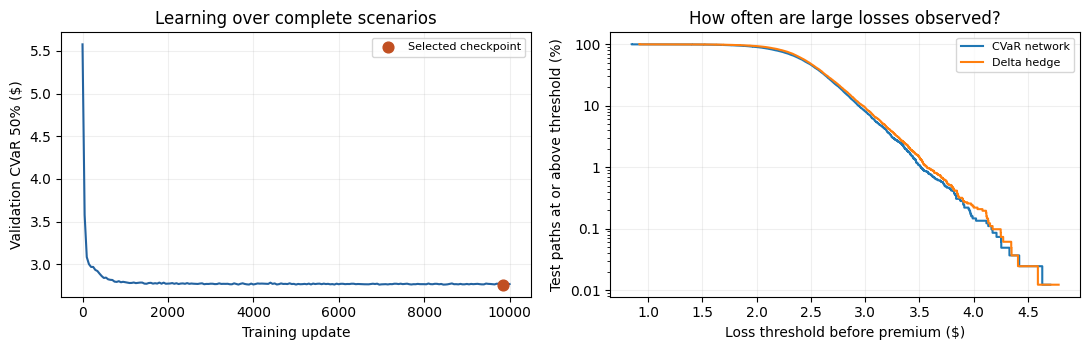

**Interpretation.** The left curve moves from CVaR 5.577 to a selected minimum of 2.761 dollars at update 9850. The right panel compares the complete test-loss distributions. At the $3$ dollar threshold, 8.11% of CVaR-network paths and 9.34% of delta-hedge paths lie at or above it. Their test CVaRs are 2.770 and 2.793 dollars. The CVaR objective summarizes the worst half of losses; it does not require its curve to be lower at every threshold. The final point of each curve is only the largest loss in this finite test sample.

In [9]:
cvar_comparison = {
    "CVaR network": test_results["CVaR network"],
    "Delta hedge": test_results["Delta hedge"],
}
plot_experiment(cvar_run, "CVaR 50%", cvar_comparison)

display(Markdown(
    f"**Interpretation.** The left curve moves from CVaR "
    f"{cvar_run['history']['risk'].iloc[0]:.3f} to a selected minimum of "
    f"{cvar_run['history']['risk'].min():.3f} dollars at update {cvar_run['best_update']}. "
    f"The right panel compares the complete test-loss distributions. At the $3$ dollar threshold, "
    f"{100 * (cvar_losses >= 3).double().mean():.2f}% of CVaR-network paths and "
    f"{100 * (delta_losses >= 3).double().mean():.2f}% of delta-hedge paths lie at or above it. "
    f"Their test CVaRs are {cvar(cvar_losses):.3f} and {cvar(delta_losses):.3f} dollars. "
    "The CVaR objective summarizes the worst half of losses; it does not require its curve "
    "to be lower at every threshold. The final point of each curve is only the largest "
    "loss in this finite test sample."
))

### Experiment 2 graph — entropic learning and test losses

The left panel uses entropic risk, so its numerical height should not be compared directly with the previous CVaR curve. The right panel places both trained strategies and the delta benchmark on the same loss-frequency axes.

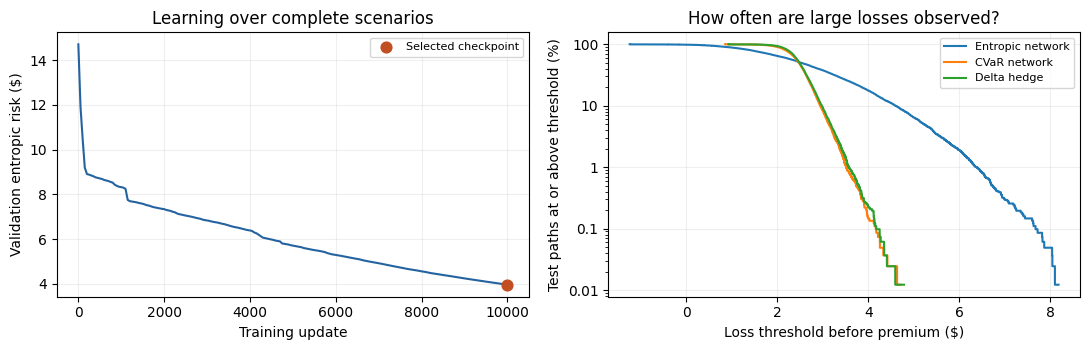

**Interpretation.** The left curve moves from entropic risk 14.701 to a selected minimum of 3.960 dollars at update 10000. On the right, the frequencies of losses of at least $3$ dollars are 37.76% for the entropic network, 8.11% for the CVaR network, and 9.34% for delta. Their empirical entropic risks are 3.863, 2.556, and 2.590 dollars. The risk score uses all observed losses and gives greater weight to large ones; one threshold alone cannot establish which strategy has lower entropic risk. Sparse points at the far right represent rare outcomes in this sample. The best validation checkpoint occurs at the final update, so this curve does not establish convergence. These achieved scores do not establish which risk objective can produce the best hedge.

In [10]:
entropic_comparison = {
    "Entropic network": test_results["Entropic network"],
    "CVaR network": test_results["CVaR network"],
    "Delta hedge": test_results["Delta hedge"],
}
plot_experiment(entropic_run, "entropic risk", entropic_comparison)

convergence_note = ""
if entropic_run["best_update"] == number_of_updates:
    convergence_note = (
        "The best validation checkpoint occurs at the final update, so this curve "
        "does not establish convergence. These achieved scores do not establish "
        "which risk objective can produce the best hedge."
    )

display(Markdown(
    f"**Interpretation.** The left curve moves from entropic risk "
    f"{entropic_run['history']['risk'].iloc[0]:.3f} to a selected minimum of "
    f"{entropic_run['history']['risk'].min():.3f} dollars at update {entropic_run['best_update']}. "
    f"On the right, the frequencies of losses of at least $3$ dollars are "
    f"{100 * (entropic_losses >= 3).double().mean():.2f}% for the entropic network, "
    f"{100 * (cvar_losses >= 3).double().mean():.2f}% for the CVaR network, and "
    f"{100 * (delta_losses >= 3).double().mean():.2f}% for delta. "
    f"Their empirical entropic risks are {entropic_risk(entropic_losses):.3f}, "
    f"{entropic_risk(cvar_losses):.3f}, and {entropic_risk(delta_losses):.3f} dollars. "
    "The risk score uses all observed losses and gives greater weight to large ones; "
    "one threshold alone cannot establish which strategy has lower entropic risk. "
    "Sparse points at the far right represent rare outcomes in this sample. "
    + convergence_note
))

## What this first experiment establishes

We have a complete, reproducible comparison of two ways to train the same daily network architecture. Lower validation risk shows improvement relative to initialization. The independent test table measures how those selected strategies compare with a classical hedge, including transaction costs. A finite training run need not beat delta, and a single seed does not establish statistical superiority.

Next we can repeat seeds, vary trading costs as in Section 5.3, or add the Heston simulator and its hedge benchmark. Multi-stock portfolios, portfolio compression, and a Bellman value network can then be studied as explicit extensions of this baseline.